<a href="https://colab.research.google.com/github/emilianomtz0189/pld-monitoreo-transaccional/blob/main/notebooks/01_descarga_y_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/emilianomtz0189/pld-monitoreo-transaccional/blob/main/notebooks/01_descarga_y_exploracion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Descarga de datos y exploración

**Proyecto:** sistema de monitoreo transaccional para **Prevención de Lavado de Dinero (PLD)** con el dataset sintético *SAML-D* de Kaggle.

**Objetivo de esta etapa:** conocer el universo transaccional antes de diseñar controles. El **enfoque basado en riesgo** pide calibrar las reglas de monitoreo a la operación real de la institución: cuánto se mueve, por qué canales, hacia qué países y con qué frecuencia aparecen operaciones sospechosas.

**En este notebook:**
1. Preparar el entorno y cargar ~9.5 millones de transacciones con tipos de dato optimizados.
2. Volumen y desbalance: qué tan raras son las operaciones sospechosas.
3. Riesgo por canal (tipo de pago), geografía y moneda.
4. Montos.
5. Tipologías de lavado y verificación de fuga de información.
6. Vista por cuenta y por mes (insumo para las etapas 3 y 4).

> **Regla de oro:** la columna `tipologia` revela la etiqueta. Se usa solo para analizar resultados; **nunca** entra a una regla ni a un modelo.

> **Alcance:** SAML-D es un dataset sintético con montos en libras esterlinas y geografía centrada en Reino Unido. Las referencias a la regulación mexicana son ilustrativas.

## 1. Entorno

En Colab se hacen dos cosas al inicio de cada sesión:
- **Conectar Google Drive**, donde se respalda el dataset procesado y los resultados (los datos no se suben a GitHub).
- **Clonar el repositorio**, para trabajar con la misma estructura de carpetas que en GitHub (`data/`, `src/`, `notebooks/`, `resultados/`).

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "pld-monitoreo-transaccional"
CARPETA_DRIVE = Path("/content/drive/MyDrive/pld-monitoreo-transaccional")  # Respaldo de datos y resultados

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q  # Trae los últimos cambios de GitHub
    os.chdir(ruta_repo)
else:
    CARPETA_DRIVE = None
    if Path.cwd().name == "notebooks":
        os.chdir("..")  # En local, el notebook se ejecuta desde notebooks/

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/pld-monitoreo-transaccional


### Librerías

Se instalan desde `requirements.txt` para que cualquier sesión use las mismas versiones.

In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.datos import medir_ahorro_memoria, preparar_datos, resumen_estructura, respaldar_resultados
from src.eda import (
    FORMATO_PERFIL,
    agregar_banderas,
    graficar_por_dia,
    graficar_mensual,
    graficar_mezcla_cuentas,
    graficar_montos,
    graficar_tasa,
    graficar_tipologia_canal,
    guardar_figura,
    guardar_metricas,
    perfil_riesgo,
    resumen_cuentas,
    resumen_desbalance,
    resumen_mensual,
    resumen_montos,
    resumen_tipologias,
    resumen_volumen,
    verificar_fuga_tipologia,
)

config.fijar_semilla()   # SEMILLA = 42 en src/config.py
config.crear_carpetas()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

METRICAS = {}  # Todas las cifras de esta etapa; se guardan en resultados/metricas/

### Registro de versiones

Un sistema de monitoreo debe poder **replicarse**: auditoría interna, el auditor externo y el supervisor deben obtener los mismos resultados. Copia la salida de esta celda en `requirements.txt` para fijar las versiones.

In [4]:
import importlib.metadata as metadata
import platform

paquetes = ["numpy", "pandas", "pyarrow", "matplotlib", "scikit-learn", "lightgbm", "kagglehub", "psutil"]
print(f"# Probado en Python {platform.python_version()}")
for paquete in paquetes:
    try:
        print(f"{paquete}=={metadata.version(paquete)}")
    except metadata.PackageNotFoundError:
        print(f"# {paquete}: no instalado")

# Probado en Python 3.13.18
numpy==2.4.6
pandas==2.2.3
pyarrow==23.0.1
matplotlib==3.10.0
scikit-learn==1.6.1
lightgbm==4.6.0
kagglehub==1.0.3
psutil==5.9.5


## 2. Datos

### Descarga y carga optimizada
La función `preparar_datos` usa el camino más rápido disponible:
1. Si ya existe el Parquet procesado en Drive, lo copia y lo carga (segundos).
2. Si no, descarga el CSV de Kaggle con `kagglehub`, lo procesa, lo guarda en Parquet y lo respalda en Drive. **La primera vez puede tardar varios minutos.**

Si Kaggle pide credenciales, ver `data/README.md`.

**Por qué importa la memoria:** leer ~9.5 millones de filas como texto puede agotar la RAM de Colab. Por eso cada columna se lee con su tipo:

| Columnas | Tipo | Motivo |
|---|---|---|
| Fecha, hora, monedas, países, tipo de pago, tipología | `category` | Pocos valores distintos repetidos millones de veces: se guardan como código entero + diccionario. |
| Cuentas | `int64` → `int32` si caben | Un `int32` solo llega a 2,147,483,647; la función revisa antes de convertir. |
| Monto | `float32` | Suficiente para guardar libras con centavos; los totales se suman en `float64`. |
| Etiqueta | `int8` | Solo toma 0 o 1. |

Si Colab se queda sin memoria, cambia `POR_PARTES = True`: lee de un millón en un millón (más lento, más seguro).

In [5]:
POR_PARTES = False

df = preparar_datos(CARPETA_DRIVE, por_partes=POR_PARTES)
memoria_mb = df.memory_usage(deep=True).sum() / 1e6
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Memoria: {memoria_mb:,.0f} MB")
df.head()

100%|██████████| 193M/193M [00:01<00:00, 142MB/s]

Extracting files...


Descargado de Kaggle: SAML-D.csv (996 MB)
Guardado: data/processed/transacciones.parquet (187 MB)
Respaldo en Drive: /content/drive/MyDrive/pld-monitoreo-transaccional/transacciones.parquet
Filas: 9,504,852 | Columnas: 11 | Memoria: 333 MB


,fecha_hora,cuenta_origen,cuenta_destino,monto,moneda_pago,moneda_recibida,pais_banco_origen,pais_banco_destino,tipo_pago,es_sospechosa,tipologia
0,2022-10-07 10:35:19,8724731955,2769355426,1459.150024,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits
1,2022-10-07 10:35:20,1491989064,8401255335,6019.640137,UK pounds,Dirham,UK,UAE,Cross-border,0,Normal_Fan_Out
2,2022-10-07 10:35:20,287305149,4404767002,14328.440430,UK pounds,UK pounds,UK,UK,Cheque,0,Normal_Small_Fan_Out
3,2022-10-07 10:35:21,5376652437,9600420220,11895.000000,UK pounds,UK pounds,UK,UK,ACH,0,Normal_Fan_In
4,2022-10-07 10:35:21,9614186178,3803336972,115.250000,UK pounds,UK pounds,UK,UK,Cash Deposit,0,Normal_Cash_Deposits


In [6]:
# Tipo, memoria, nulos y valores únicos por columna. El diccionario de variables está en data/README.md
resumen_estructura(df)

,tipo,memoria_mb,nulos,valores_unicos
fecha_hora,datetime64[ns],76.0,0,7753911
cuenta_origen,int64,76.0,0,292715
cuenta_destino,int64,76.0,0,652266
monto,float32,38.0,0,2314192
moneda_pago,category,9.5,0,13
moneda_recibida,category,9.5,0,13
pais_banco_origen,category,9.5,0,18
pais_banco_destino,category,9.5,0,18
tipo_pago,category,9.5,0,7
es_sospechosa,int8,9.5,0,2


In [7]:
# Medición real del ahorro de memoria en las primeras 500 mil filas (solo si el CSV está disponible en esta sesión)
ahorro = medir_ahorro_memoria()
METRICAS["ahorro_memoria"] = ahorro
print(ahorro if ahorro else "CSV no disponible en esta sesión (se cargó desde el Parquet de Drive).")

{'filas_medidas': 500000, 'mb_sin_optimizar': 244.5, 'mb_optimizado': 22.8, 'reduccion_pct': 90.7}


## 3. Volumen

El volumen define la capacidad que necesita el área de monitoreo: cuántas alertas al día puede revisar un equipo determina qué tan estrictas pueden ser las reglas.

In [8]:
volumen, por_dia = resumen_volumen(df)
METRICAS["volumen"] = volumen
pd.Series(volumen, name="valor").to_frame()

,valor
transacciones,9504852
cuentas_unicas,855460
cuentas_que_envian,292715
cuentas_que_reciben,652266
fecha_inicial,2022-10-07 10:35:19
fecha_final,2023-08-23 10:57:12
dias_con_operacion,321
transacciones_por_dia_promedio,29610.1
transacciones_por_dia_minimo,8400
transacciones_por_dia_maximo,36645


Gráfica guardada: resultados/figuras/01_transacciones_por_dia.png


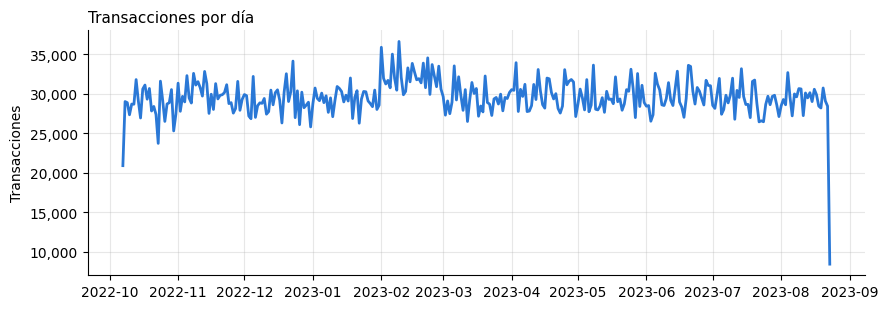

In [9]:
fig = graficar_por_dia(por_dia)
guardar_figura(fig, "01_transacciones_por_dia.png")
plt.show()

## 4. Desbalance

Con operaciones sospechosas tan escasas, la **exactitud** (*accuracy*) engaña: un sistema que nunca alerta acertaría casi siempre y no detectaría nada. Por eso el proyecto se evalúa con:
- **Precisión:** de las alertas generadas, qué porcentaje eran realmente sospechosas. Mide la carga de falsos positivos sobre los analistas.
- **Recall (sensibilidad):** de todas las operaciones sospechosas, qué porcentaje se detectó. Mide el riesgo de no identificar algo que debía analizarse y, en su caso, reportarse.

> En una institución real no existe una etiqueta perfecta: lo más cercano son los casos que el área de PLD dictaminó y reportó. En SAML-D, por ser sintético, la etiqueta es completa.

In [10]:
desbalance = resumen_desbalance(df)
METRICAS["desbalance"] = desbalance
TASA_GLOBAL = df[config.COLUMNA_OBJETIVO].mean()
pd.Series(desbalance, name="valor").to_frame()

,valor
transacciones_normales,9.494979e+06
transacciones_sospechosas,9.873000e+03
tasa_sospechosa_pct,1.039000e-01
una_de_cada,9.627000e+02
exactitud_si_nada_es_sospechoso_pct,9.989610e+01
monto_sospechoso,4.007220e+08
monto_sospechoso_pct_del_total,4.811000e-01


## 5. Riesgo por canal: tipo de pago

El efectivo es el canal tradicionalmente más vigilado porque no deja rastro del origen de los fondos; por eso la regulación mexicana le dedica reportes específicos (se detalla en la etapa 2).

La columna **`veces_el_promedio`** compara la tasa sospechosa del canal contra la tasa global: es la forma directa de priorizar controles en un enfoque basado en riesgo.

In [11]:
por_canal = perfil_riesgo(df, "tipo_pago")
METRICAS["tipo_pago"] = por_canal[["transacciones", "sospechosas", "tasa_sospechosa_pct", "veces_el_promedio"]].round(4).reset_index().to_dict("records")
por_canal.style.format(FORMATO_PERFIL)

,transacciones,sospechosas,monto_total,monto_mediano,pct_transacciones,pct_de_las_sospechosas,tasa_sospechosa_pct,veces_el_promedio
tipo_pago,,,,,,,,
Cash Deposit,"225,206","1,405","£485,809,046","£1,766.90",2.37%,14.23%,0.6239%,6.01x
Cash Withdrawal,"300,477","1,334","£46,118,126",£139.27,3.16%,13.51%,0.4440%,4.27x
Cross-border,"933,931","2,628","£9,476,591,292","£7,453.03",9.83%,26.62%,0.2814%,2.71x
ACH,"2,008,807","1,159","£18,272,052,012","£6,360.19",21.13%,11.74%,0.0577%,0.56x
Credit card,"2,012,909","1,136","£18,308,924,933","£6,354.61",21.18%,11.51%,0.0564%,0.54x
Debit card,"2,012,103","1,124","£18,372,338,761","£6,352.35",21.17%,11.38%,0.0559%,0.54x
Cheque,"2,011,419","1,087","£18,328,875,958","£6,350.21",21.16%,11.01%,0.0540%,0.52x


Gráfica guardada: resultados/figuras/02_tasa_por_tipo_pago.png


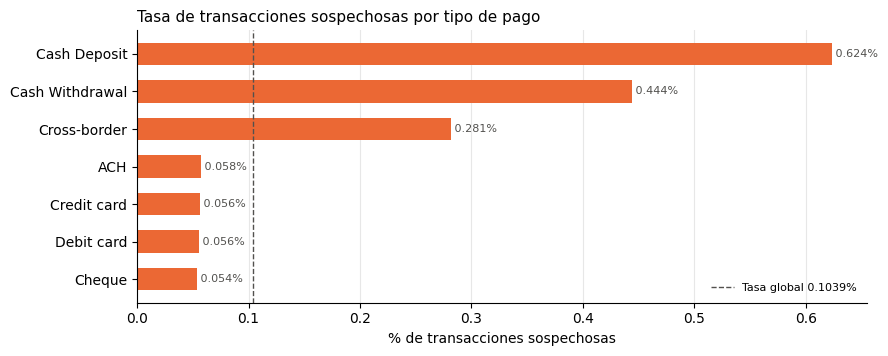

In [12]:
fig = graficar_tasa(por_canal, "Tasa de transacciones sospechosas por tipo de pago", TASA_GLOBAL)
guardar_figura(fig, "02_tasa_por_tipo_pago.png")
plt.show()

## 6. Riesgo geográfico y de moneda

Las operaciones transfronterizas, y en especial las que involucran **jurisdicciones de alto riesgo o no cooperantes** (listas del GAFI), son un factor de riesgo clásico: dificultan rastrear origen y destino de los recursos.

- **Internacional:** banco de origen y de destino en distinto país.
- **Cambio de moneda:** moneda pagada distinta de la recibida.

In [13]:
df = agregar_banderas(df)

for columna in ["es_internacional", "cambio_moneda"]:
    tabla = perfil_riesgo(df, columna)
    METRICAS[columna] = tabla[["transacciones", "pct_transacciones", "tasa_sospechosa_pct", "veces_el_promedio"]].round(4).reset_index().to_dict("records")
    print(f"\n{columna} (1 = sí)")
    display(tabla[["transacciones", "pct_transacciones", "sospechosas", "tasa_sospechosa_pct", "veces_el_promedio"]].style.format(FORMATO_PERFIL))


es_internacional (1 = sí)


,transacciones,pct_transacciones,sospechosas,tasa_sospechosa_pct,veces_el_promedio
es_internacional,,,,,
1,"934,348",9.83%,"3,045",0.3259%,3.14x
0,"8,570,504",90.17%,"6,828",0.0797%,0.77x



cambio_moneda (1 = sí)


,transacciones,pct_transacciones,sospechosas,tasa_sospechosa_pct,veces_el_promedio
cambio_moneda,,,,,
1,"1,085,862",11.42%,"3,657",0.3368%,3.24x
0,"8,418,990",88.58%,"6,216",0.0738%,0.71x


In [14]:
# País del banco que RECIBE (a dónde va el dinero). Se excluyen países con menos de 1,000 transacciones: su tasa sería poco confiable.
MINIMO_TRANSACCIONES = 1_000
por_pais_destino = perfil_riesgo(df, "pais_banco_destino", minimo=MINIMO_TRANSACCIONES)
METRICAS["pais_banco_destino"] = por_pais_destino[["transacciones", "tasa_sospechosa_pct", "veces_el_promedio"]].round(4).reset_index().to_dict("records")
por_pais_destino.style.format(FORMATO_PERFIL)

,transacciones,sospechosas,monto_total,monto_mediano,pct_transacciones,pct_de_las_sospechosas,tasa_sospechosa_pct,veces_el_promedio
pais_banco_destino,,,,,,,,
Nigeria,"38,272",251,"£385,004,396","£7,355.67",0.40%,2.54%,0.6558%,6.31x
Morocco,"38,704",253,"£389,138,903","£7,454.42",0.41%,2.56%,0.6537%,6.29x
Albania,"38,783",235,"£376,975,731","£7,145.32",0.41%,2.38%,0.6059%,5.83x
UAE,"35,897",195,"£358,298,923","£7,459.98",0.38%,1.98%,0.5432%,5.23x
Mexico,"38,385",197,"£388,908,778","£7,429.83",0.40%,2.00%,0.5132%,4.94x
Turkey,"35,586",177,"£357,778,005","£7,328.88",0.37%,1.79%,0.4974%,4.79x
Pakistan,"38,980",169,"£382,921,634","£7,466.26",0.41%,1.71%,0.4336%,4.17x
Netherlands,"37,314",148,"£377,908,242","£7,330.30",0.39%,1.50%,0.3966%,3.82x
Austria,"38,844",154,"£380,402,775","£7,511.61",0.41%,1.56%,0.3965%,3.82x


Gráfica guardada: resultados/figuras/03_tasa_por_pais_destino.png


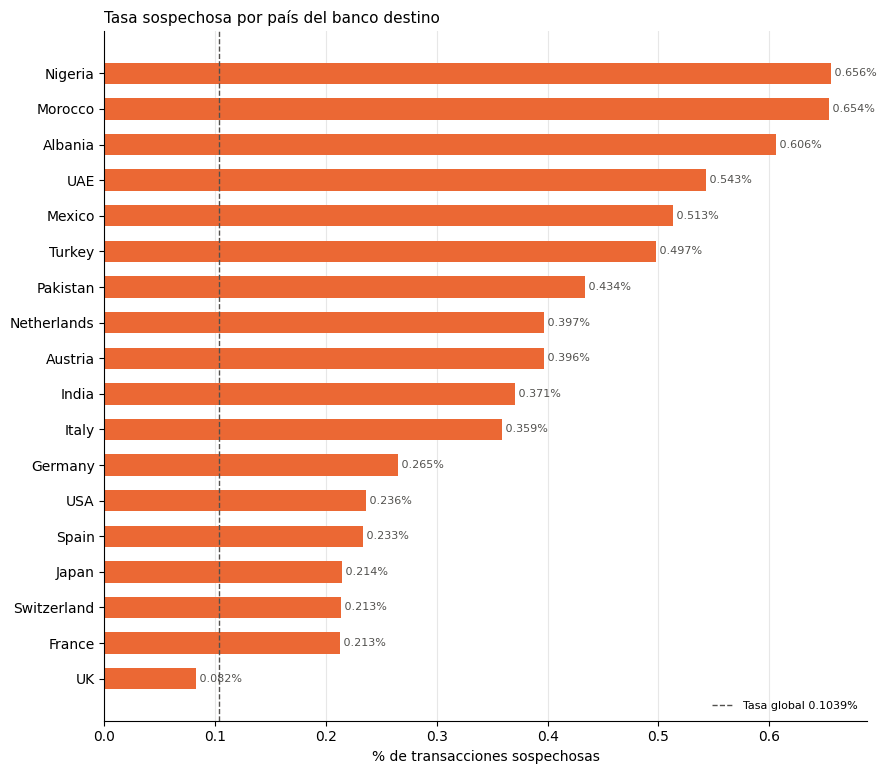

In [15]:
fig = graficar_tasa(por_pais_destino, "Tasa sospechosa por país del banco destino", TASA_GLOBAL)
guardar_figura(fig, "03_tasa_por_pais_destino.png")
plt.show()

In [16]:
# País del banco que ENVÍA (de dónde viene el dinero)
por_pais_origen = perfil_riesgo(df, "pais_banco_origen", minimo=MINIMO_TRANSACCIONES)
METRICAS["pais_banco_origen"] = por_pais_origen[["transacciones", "tasa_sospechosa_pct", "veces_el_promedio"]].round(4).reset_index().to_dict("records")
por_pais_origen.style.format(FORMATO_PERFIL)

,transacciones,sospechosas,monto_total,monto_mediano,pct_transacciones,pct_de_las_sospechosas,tasa_sospechosa_pct,veces_el_promedio
pais_banco_origen,,,,,,,,
Morocco,"18,437",55,"£194,789,167","£7,629.93",0.19%,0.56%,0.2983%,2.87x
Mexico,"17,662",44,"£187,436,695","£7,695.10",0.19%,0.45%,0.2491%,2.40x
Netherlands,"16,770",41,"£185,554,196","£7,816.74",0.18%,0.42%,0.2445%,2.35x
India,"17,596",42,"£185,609,001","£7,651.65",0.19%,0.43%,0.2387%,2.30x
Italy,"18,895",45,"£198,252,505","£7,659.28",0.20%,0.46%,0.2382%,2.29x
Germany,"19,259",43,"£209,235,454","£8,155.32",0.20%,0.44%,0.2233%,2.15x
Austria,"18,050",38,"£182,588,954","£7,229.55",0.19%,0.38%,0.2105%,2.03x
Japan,"18,468",38,"£188,719,330","£7,432.60",0.19%,0.38%,0.2058%,1.98x
Switzerland,"20,503",41,"£226,305,975","£7,943.87",0.22%,0.42%,0.2000%,1.93x


## 7. Montos

La intuición dice "lavado = montos grandes", pero varias tipologías hacen lo contrario: **fraccionan** en montos menores para no rebasar umbrales de reporte. Si los montos sospechosos se parecen a los normales, una regla basada solo en monto alto será insuficiente.

In [17]:
montos = resumen_montos(df)
METRICAS["montos"] = montos.round(2).to_dict()
montos.style.format("{:,.2f}")

es_sospechosa,normal,sospechosa
count,"9,494,979.00","9,873.00"
mean,"8,729.88","40,587.67"
std,"21,365.19","419,177.97"
min,3.73,15.82
1%,69.10,47.99
5%,217.55,107.38
25%,"2,142.93","2,723.79"
50%,"6,114.63","5,322.79"
75%,"10,458.95","9,789.67"
95%,"22,031.33","39,698.43"


Gráfica guardada: resultados/figuras/04_distribucion_montos.png


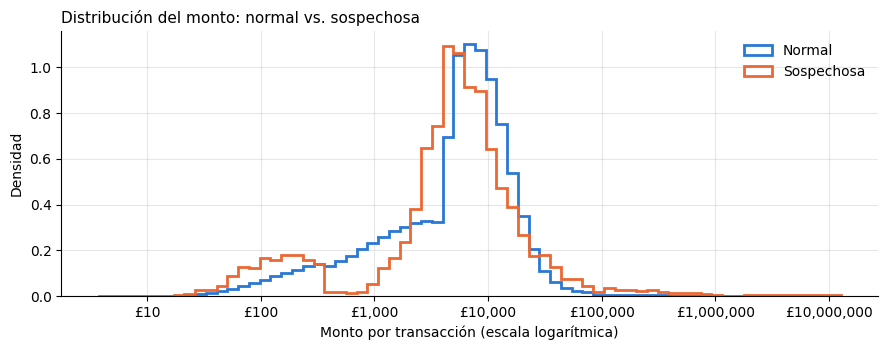

In [18]:
fig = graficar_montos(df)
guardar_figura(fig, "04_distribucion_montos.png")
plt.show()

In [19]:
# Monto mediano por tipo de pago: normal (0) vs. sospechosa (1)
df.pivot_table(index="tipo_pago", columns=config.COLUMNA_OBJETIVO, values="monto",
               aggfunc="median", observed=True).round(2)

es_sospechosa,0,1
tipo_pago,,
ACH,6359.479980,7541.189941
Cash Deposit,1758.079956,3035.189941
Cash Withdrawal,139.270004,139.119995
Cheque,6349.500000,7451.160156
Credit card,6353.759766,7838.299805
Cross-border,7457.520020,5757.319824
Debit card,6351.490234,7732.439941


## 8. Tipologías (solo análisis)

Una **tipología** es un patrón conocido de lavado: fraccionar depósitos, concentrar fondos de muchas cuentas en una, mover recursos en cadena, entre otros. Las autoridades publican tipologías para orientar a las instituciones sobre qué buscar.

### Verificación de fuga de información
Si cada tipología es 100 % normal o 100 % sospechosa, conocer la tipología equivale a conocer la respuesta. Esta verificación justifica excluirla de reglas y modelos.

In [20]:
fuga = verificar_fuga_tipologia(df)
es_pura = fuga["pct_sospechosa"].isin([0, 100]).all()
METRICAS["tipologias"] = {
    "total": int(len(fuga)),
    "normales": int((fuga["pct_sospechosa"] == 0).sum()),
    "sospechosas": int((fuga["pct_sospechosa"] == 100).sum()),
    "revela_la_etiqueta": bool(es_pura),
}
print(METRICAS["tipologias"])
fuga.style.format({"transacciones": "{:,.0f}", "pct_sospechosa": "{:.1f}%"})

{'total': 28, 'normales': 11, 'sospechosas': 17, 'revela_la_etiqueta': True}


,transacciones,pct_sospechosa
tipologia,,
Structuring,"1,870",100.0%
Cash_Withdrawal,"1,334",100.0%
Deposit-Send,945,100.0%
Smurfing,932,100.0%
Layered_Fan_In,656,100.0%
Layered_Fan_Out,529,100.0%
Stacked Bipartite,506,100.0%
Behavioural_Change_1,394,100.0%
Bipartite,383,100.0%


### Perfil de las tipologías sospechosas
Este perfil sirve en la etapa 2 para medir qué tipologías detecta cada regla.

In [21]:
tipologias = resumen_tipologias(df)
METRICAS["tipologias"]["detalle"] = tipologias[["transacciones", "pct_de_las_sospechosas", "canal_principal", "pct_internacional"]].round(2).reset_index().to_dict("records")
tipologias.style.format({"transacciones": "{:,.0f}", "monto_mediano": "£{:,.2f}", "cuentas_que_envian": "{:,.0f}",
                         "pct_de_las_sospechosas": "{:.2f}%", "pct_internacional": "{:.1f}%"})

,transacciones,monto_mediano,cuentas_que_envian,pct_de_las_sospechosas,canal_principal,pct_internacional,descripcion
tipologia,,,,,,,
Structuring,"1,870","£4,800.35","1,870",18.94%,Cross-border,38.7%,Fraccionamiento: dividir una suma grande en depósitos menores para no rebasar umbrales.
Cash_Withdrawal,"1,334",£139.12,88,13.51%,Cash Withdrawal,30.9%,Retiro en efectivo: los fondos salen del sistema en efectivo.
Deposit-Send,945,"£6,331.86",563,9.57%,Cash Deposit,35.8%,Depósito y envío: entra efectivo y sale rápido por transferencia.
Smurfing,932,"£2,629.42",63,9.44%,Cash Deposit,0.5%,Pitufeo: varias personas o cuentas hacen depósitos chicos que terminan en una misma cuenta.
Layered_Fan_In,656,"£10,726.06",491,6.64%,ACH,19.7%,Dispersión en capas: una cuenta reparte a muchas y estas vuelven a repartir.
Layered_Fan_Out,529,"£6,729.77",215,5.36%,Cross-border,25.3%,Dispersión en capas: una cuenta reparte a muchas y estas vuelven a repartir.
Stacked Bipartite,506,"£7,882.61",187,5.13%,Debit card,15.2%,Bipartita apilada: varias capas de grupos de cuentas que se transfieren entre sí.
Behavioural_Change_1,394,"£3,117.91",53,3.99%,Cross-border,65.5%,Cambio de comportamiento: la cuenta se aparta de su patrón histórico.
Bipartite,383,"£8,900.82",74,3.88%,Cross-border,24.0%,Bipartita: un grupo de cuentas transfiere a otro grupo.


Gráfica guardada: resultados/figuras/05_tipologia_por_canal.png


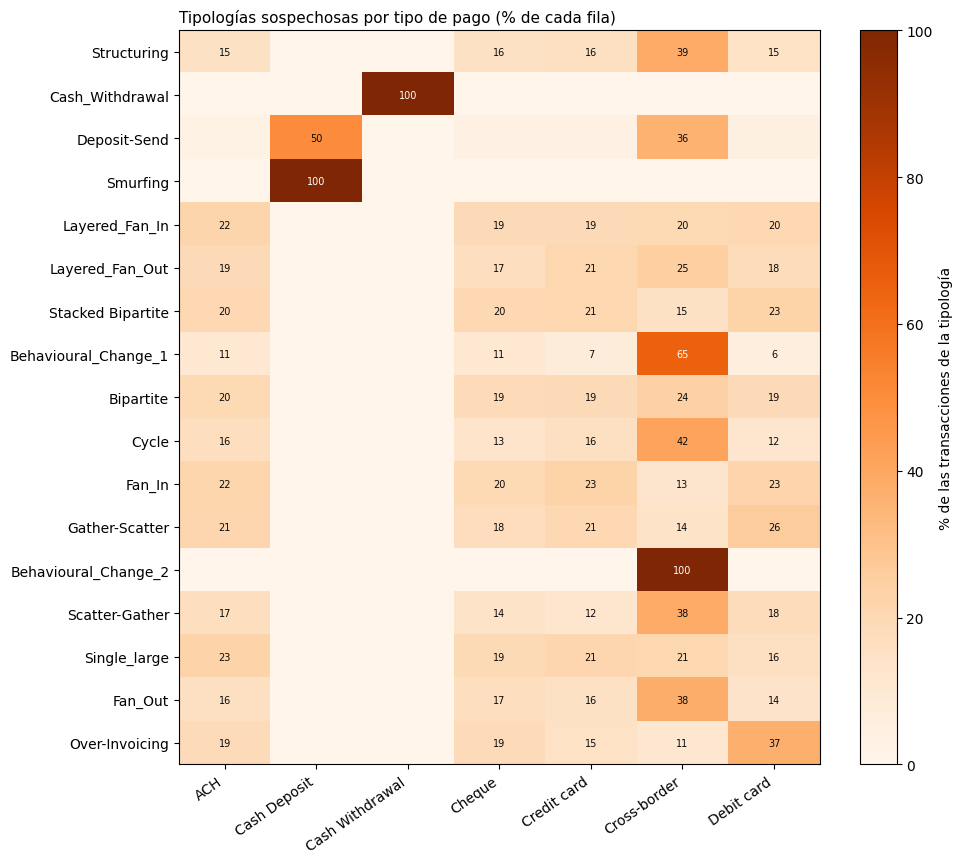

In [22]:
fig = graficar_tipologia_canal(df, orden=list(tipologias.index))
guardar_figura(fig, "05_tipologia_por_canal.png")
plt.show()

## 9. Vista por cuenta

En la práctica, el analista no revisa transacciones aisladas sino **casos por cliente**: abre el expediente y revisa todo su historial. Por eso importa cuántas cuentas están involucradas y si las cuentas con operaciones sospechosas también realizan operaciones normales que las camuflan.

In [23]:
cuentas, fraccion = resumen_cuentas(df)
METRICAS["cuentas"] = cuentas
pd.Series(cuentas, name="valor").to_frame()

,valor
cuentas_con_alguna_operacion_sospechosa,7902.0000
pct_del_total_de_cuentas,0.9237
cuentas_que_envian_alguna_sospechosa,4950.0000
envios_por_cuenta_mediana,12.0000
envios_por_cuenta_p99,506.0000
pct_sospechoso_de_sus_envios_mediana,0.9900
pct_de_esas_cuentas_que_tambien_operan_normal,99.9800


Gráfica guardada: resultados/figuras/06_mezcla_en_cuentas.png


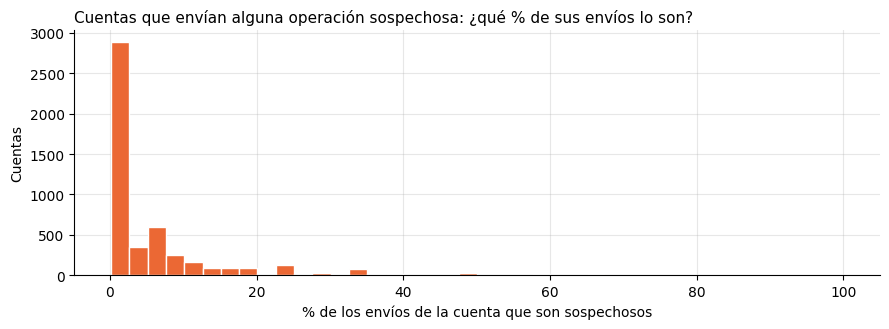

In [24]:
fig = graficar_mezcla_cuentas(fraccion)
guardar_figura(fig, "06_mezcla_en_cuentas.png")
plt.show()

## 10. Vista por mes

El modelo de la etapa 4 se entrena con meses **anteriores** y se evalúa con meses **posteriores**, como ocurriría en producción. Esta tabla muestra qué meses están completos y si la tasa sospechosa es estable en el tiempo.

In [25]:
mensual = resumen_mensual(df)
METRICAS["mensual"] = [{"mes": str(m), **{k: (round(float(v), 4) if k == "tasa_sospechosa_pct" else int(v)) for k, v in fila.items()}}
                       for m, fila in mensual.iterrows()]
mensual.style.format({"transacciones": "{:,.0f}", "sospechosas": "{:,.0f}", "tasa_sospechosa_pct": "{:.4f}%"})

,transacciones,sospechosas,dias_con_datos,tasa_sospechosa_pct
mes,,,,
2022-10,"708,654",694,25,0.0979%
2022-11,"897,621",794,30,0.0885%
2022-12,"900,341",907,31,0.1007%
2023-01,"908,320",940,31,0.1035%
2023-02,"904,806",946,28,0.1046%
2023-03,"908,562",927,31,0.1020%
2023-04,"902,883",962,30,0.1065%
2023-05,"917,601",866,31,0.0944%
2023-06,"897,243","1,024",30,0.1141%


Gráfica guardada: resultados/figuras/07_tasa_mensual.png


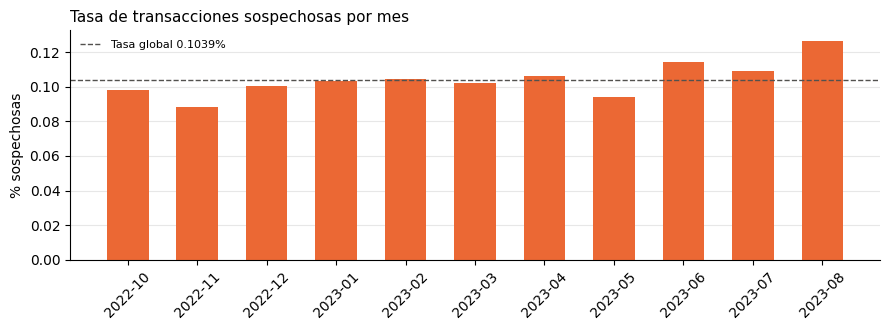

In [26]:
fig = graficar_mensual(mensual, TASA_GLOBAL)
guardar_figura(fig, "07_tasa_mensual.png")
plt.show()

## 11. Resumen y guardado

Todas las cifras de este notebook se guardan en `resultados/metricas/01_exploracion.json`, que es la única fuente de cifras para el README. También se respaldan en Drive.

In [27]:
guardar_metricas(METRICAS, "01_exploracion.json")
if CARPETA_DRIVE is not None:
    respaldar_resultados(CARPETA_DRIVE)

v, d, c = METRICAS["volumen"], METRICAS["desbalance"], METRICAS["cuentas"]
canal = por_canal.index[0]
print(f'''
RESUMEN ETAPA 1
- {v["transacciones"]:,} transacciones de {v["cuentas_unicas"]:,} cuentas, del {v["fecha_inicial"][:10]} al {v["fecha_final"][:10]} ({v["dias_con_operacion"]} días).
- Promedio de {v["transacciones_por_dia_promedio"]:,} transacciones por día.
- {d["transacciones_sospechosas"]:,} sospechosas = {d["tasa_sospechosa_pct"]}% (una de cada {d["una_de_cada"]:,}).
- Un sistema que nunca alerta tendría {d["exactitud_si_nada_es_sospechoso_pct"]}% de exactitud.
- Canal con mayor tasa sospechosa: {canal} ({por_canal.loc[canal, "veces_el_promedio"]:.2f} veces el promedio).
- {METRICAS["tipologias"]["total"]} tipologías ({METRICAS["tipologias"]["sospechosas"]} sospechosas); ¿revelan la etiqueta?: {METRICAS["tipologias"]["revela_la_etiqueta"]}.
- {c["cuentas_con_alguna_operacion_sospechosa"]:,} cuentas con alguna operación sospechosa ({c["pct_del_total_de_cuentas"]}% del total).
''')

Métricas guardadas: resultados/metricas/01_exploracion.json
Resultados respaldados en /content/drive/MyDrive/pld-monitoreo-transaccional/resultados

RESUMEN ETAPA 1
- 9,504,852 transacciones de 855,460 cuentas, del 2022-10-07 al 2023-08-23 (321 días).
- Promedio de 29,610.1 transacciones por día.
- 9,873 sospechosas = 0.1039% (una de cada 962.7).
- Un sistema que nunca alerta tendría 99.8961% de exactitud.
- Canal con mayor tasa sospechosa: Cash Deposit (6.01 veces el promedio).
- 28 tipologías (17 sospechosas); ¿revelan la etiqueta?: True.
- 7,902 cuentas con alguna operación sospechosa (0.9237% del total).



**Siguiente paso:** notebook `02_reglas_monitoreo.ipynb`: reglas de monitoreo por tipología y su medición con precisión, recall y alertas por día.

> Los archivos de `data/` no se suben a GitHub. En una sesión nueva de Colab basta con volver a ejecutar este notebook: el Parquet respaldado en Drive se carga en segundos.